In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,hinge_loss
from sklearn.svm import SVC

In [7]:
zdf=pd.read_csv(r"C:\Users\DELL\Downloads\Non_linear_SVM_Dataset.csv")
df

,X1,X2,Y
0,0.830858,-0.334342,1.0
1,0.991710,0.879000,0.0
2,1.107245,-0.470344,1.0
3,-0.140899,1.033148,0.0
4,0.405592,1.328529,0.0
...,...,...,...
495,0.265123,1.023197,0.0
496,0.193576,-0.011663,1.0
497,0.345548,-0.128434,1.0
498,1.403890,-0.466993,1.0


In [8]:
df.shape

(500, 3)

In [9]:
df.head()

,X1,X2,Y
0,0.830858,-0.334342,1.0
1,0.991710,0.879000,0.0
2,1.107245,-0.470344,1.0
3,-0.140899,1.033148,0.0
4,0.405592,1.328529,0.0


In [10]:
###info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      500 non-null    float64
 1   X2      500 non-null    float64
 2   Y       500 non-null    float64
dtypes: float64(3)
memory usage: 11.8 KB


In [11]:
##duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
###misssing values
df.isnull().sum()

X1    0
X2    0
Y     0
dtype: int64

<Axes: >

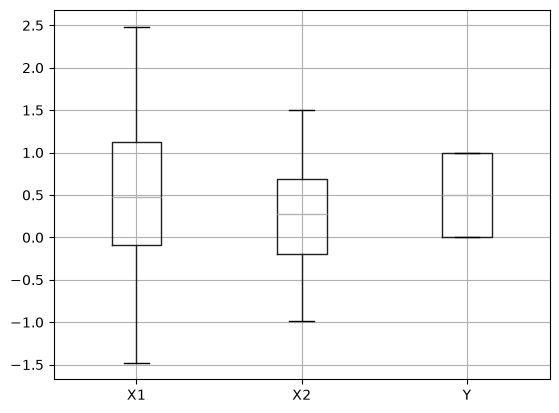

In [13]:
##outliers
df.boxplot()

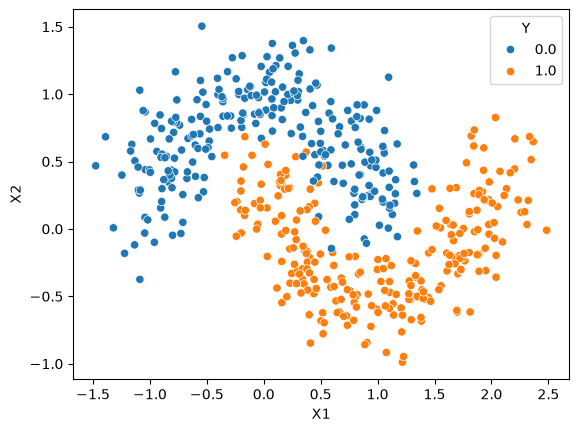

In [14]:
##scatter plot
sns.scatterplot(data=df,x=df.X1,y=df.X2,hue=df.Y)
plt.show()

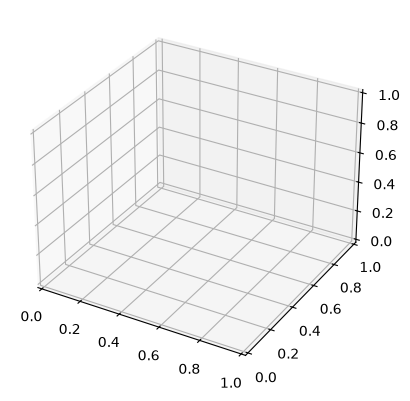

In [15]:
##3D.plot
fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
plt.show()

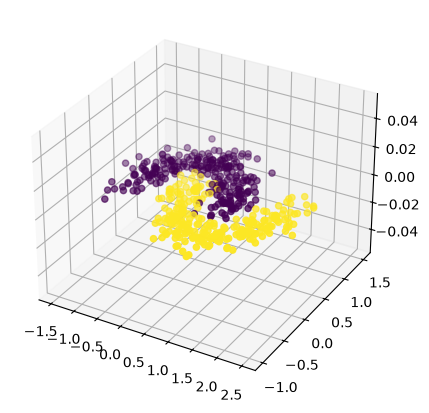

In [16]:
fig=plt.figure(figsize=(5,5))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
plt.show()

In [17]:
features=df.drop(columns=['Y'])
target=df[['Y']]


In [18]:
x_train,x_test,y_train,y_test= train_test_split(features,target,train_size=0.8,random_state=100,stratify=df.Y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 2)
(100, 2)
(400, 1)
(100, 1)


In [19]:
#### Linear SVC
linear_svc= SVC(kernel='linear',C=1)
linear_svc.fit(x_train,y_train)
y_pred_lin= linear_svc.predict(x_test)
accuracy_score(y_test,y_pred_lin)

0.81

In [20]:
##POLY SVC
poly_svc= SVC(kernel='poly',C=1,gamma=0.2)
poly_svc.fit(x_train,y_train)
y_pred_pol= poly_svc.predict(x_test)
accuracy_score(y_test,y_pred_pol)

0.72

In [21]:
### rbf SVC
rbf_svc= SVC(kernel='rbf',C=1,gamma=0.9)
rbf_svc.fit(x_train,y_train)
y_pred_rbf= rbf_svc.predict(x_test)
accuracy_score(y_test,y_pred_rbf)

0.97

In [22]:
### rbf SVC
rbf_svc= SVC(kernel='rbf',C=1,gamma=0.9)
rbf_svc.fit(x_train,y_train)
y_pred= rbf_svc.predict(x_test)
accuracy_score(y_test,y_pred)

0.97

In [23]:
### Sigmoid SVC
sigmoid_svc= SVC(kernel='rbf',C=1,gamma=0.1)
sigmoid_svc.fit(x_train,y_train)
y_pred_sig= sigmoid_svc.predict(x_test)
accuracy_score(y_test,y_pred_sig)

0.85

In [24]:
#### Hing_loss--rbf SVC
hinge_loss(y_test,y_pred_rbf)

0.53

In [25]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_rbf))

              precision    recall  f1-score   support

         0.0       0.96      0.98      0.97        50
         1.0       0.98      0.96      0.97        50

    accuracy                           0.97       100
   macro avg       0.97      0.97      0.97       100
weighted avg       0.97      0.97      0.97       100



In [26]:
df.X1.min(),df.X1.max(),df.X2.min(),df.X2.max()

(np.float64(-1.4761269392401806),
 np.float64(2.48480165010424),
 np.float64(-0.9885260706545684),
 np.float64(1.504278803710552))

In [27]:

x1_min, x1_max,x2_min,x2_max=df.X1.min()-1,df.X1.max()+1,df.X2.min()-1,df.X2.max()+1

In [28]:
print(x1_min,x1_max,x2_min,x2_max)

-2.4761269392401806 3.48480165010424 -1.9885260706545684 2.5042788037105517


In [29]:
h=0.02
np.arange(1,10)

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [30]:
np.meshgrid(np.arange(x1_min,x1_max,h),np.arange(x2_min,x2_max,h))

(array([[-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        ...,
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306]], shape=(225, 299)),
 array([[-1.98852607, -1.98852607, -1.98852607, ..., -1.98852607,
         -1.98852607, -1.98852607],
        [-1.96852607, -1.96852607, -1.96852607, ..., -1.96852607,
         -1.96852607, -1.96852607],
        [-1.94852607, -1.94852607, -1.94852607, ..., -1.94852607,
         -1.94852607, -1.94852607],
        ...,
        [ 2.45147393,  2.45147393,  

In [31]:
xx,yy=np.meshgrid(np.arange(x1_min,x1_max,h),np.arange(x2_min,x2_max,h))

In [32]:
xx.shape,yy.shape

((225, 299), (225, 299))

In [33]:
z=linear_svc.predict(np.c_[np.ravel(xx),np.ravel(yy)])
z

array([1., 1., 1., ..., 0., 0., 0.], shape=(67275,))

In [34]:
xx.ndim,yy.ndim,z.ndim

(2, 2, 1)

In [35]:
z1=z.reshape(xx.shape)
z1.ndim

2

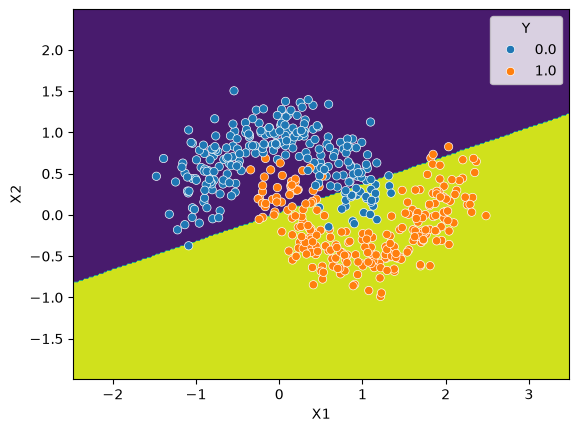

In [36]:
plt.contourf(xx,yy,z1)
sns.scatterplot(data=df,x=df.X1, y= df.X2,hue=df.Y)
plt.show()


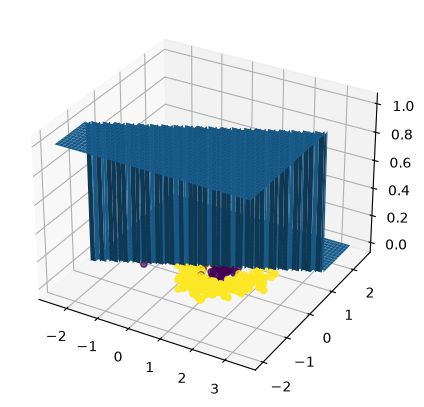

In [37]:
fig= plt.figure(figsize=(5,5))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
ax.plot_surface(xx,yy,z1)
plt.show()

In [38]:
#### Poly kernel

z= poly_svc.predict(np.c_[np.ravel(xx),np.ravel(yy)])

z

array([1., 1., 1., ..., 0., 0., 0.], shape=(67275,))

In [39]:
z1= z.reshape(xx.shape)






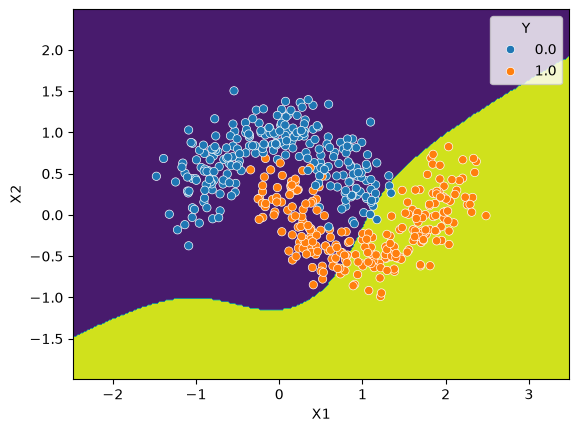

In [40]:
plt.contourf(xx,yy,z1)

sns.scatterplot(data=df,x=df.X1, y= df.X2,hue=df.Y)

plt.show()

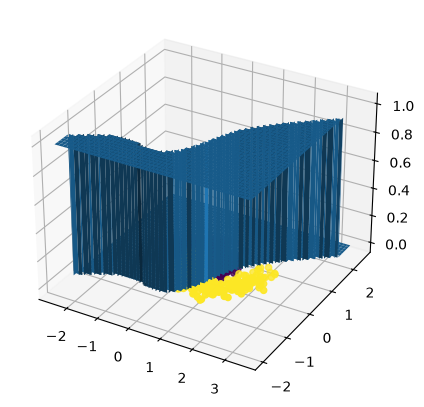

In [41]:
fig= plt.figure(figsize=(5,5))

ax=fig.add_subplot(111,projection='3d')

ax.scatter(df.X1,df.X2,c=df.Y)

ax.plot_surface(xx,yy,z1)

plt.show()

In [42]:
#### rbf kernel
z= rbf_svc.predict(np.c_[np.ravel(xx),np.ravel(yy)])
z

array([1., 1., 1., ..., 1., 1., 1.], shape=(67275,))

In [43]:
z1= z.reshape(xx.shape)

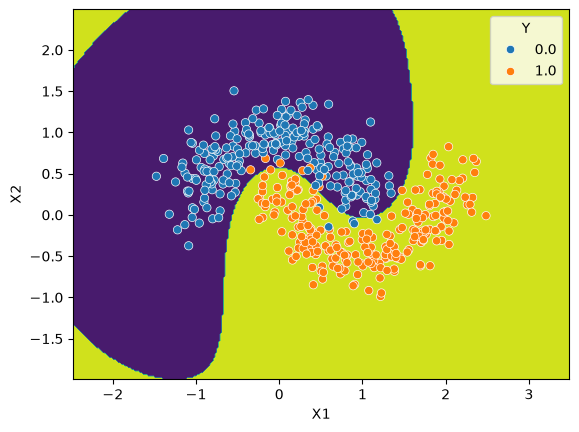

In [44]:
plt.contourf(xx,yy,z1)

sns.scatterplot(data=df,x=df.X1, y= df.X2,hue=df.Y)

plt.show()

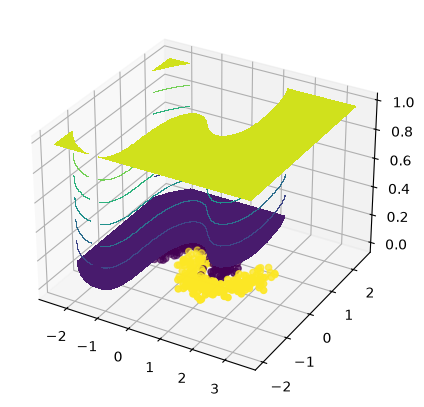

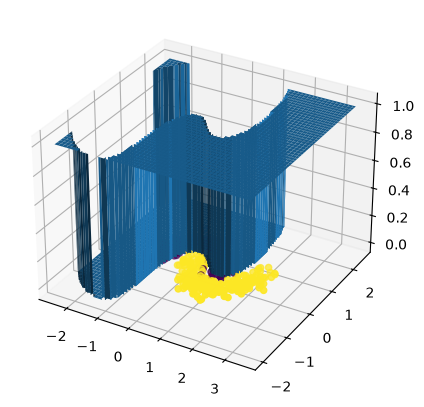

In [47]:
fig= plt.figure(figsize=(5,5))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
ax.plot_surface(xx,yy,z1)
plt.show()

In [48]:
##sigmoid
z=sigmoid_svc.predict(np.c_[np.ravel(xx),np.ravel(yy)])
z

array([1., 1., 1., ..., 1., 1., 1.], shape=(67275,))

In [51]:
z1=z.reshape(xx.shape)

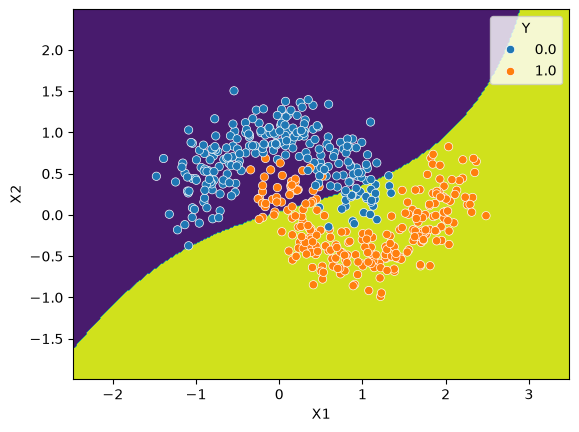

In [52]:
plt.contourf(xx,yy,z1)
sns.scatterplot(data=df,x=df.X1, y= df.X2,hue=df.Y)
plt.show()

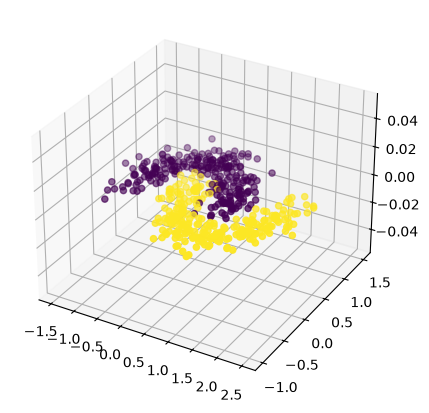

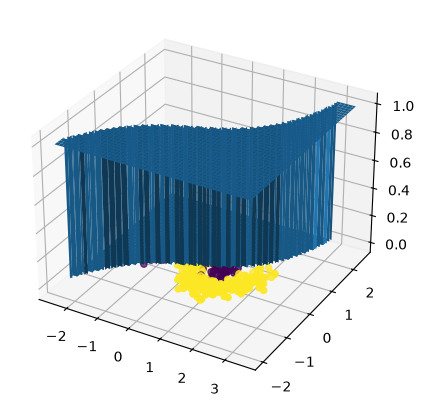

In [54]:
fig= plt.figure(figsize=(5,5))

ax=fig.add_subplot(111,projection='3d')

ax.scatter(df.X1,df.X2,c=df.Y)

ax.plot_surface(xx,yy,z1)

plt.show()